# BLACKJACK: ¡A POR EL 21 ! 🎰

<img src="blackjack.png">

## Juego hecho por: Kira Ureta Freiman (154652) y Arancha Hervás Negrete (149736) -> Por partes iguales

¡Bienvenido al Blackjack!♠️♥️♣️♦️
El objetivo es acercarse a 21 puntos sin pasarse.
Las cartas del 2 al 10 valen lo que indica su número.
Las figuras J, Q y K valen 10 puntos.
Los ases valen 11 o 1 para intentar no superar 21.
Un blackjack son 21 puntos con las dos primeras cartas.
El blackjack gana a un 21 conseguido con más cartas.
La banca pide cartas con menos de 17 y se planta con 17 o más.
Si ambos tienen blackjack, o los mismos puntos sin blackjack, hay empate.
Escribe las respuestas en minúsculas.
¡Buena suerte!🃏
¿Quieres comenzar la partida? Escribe si o no: si
Tus cartas: ['7', '2']
Tus puntos: 9
Carta visible de la banca: 3
¿Quieres pedir carta o plantarte? Escribe pedir o plantarse: pedir
Tus cartas: ['7', '2', '6']
Tus puntos: 15
¿Quieres pedir carta o plantarte? Escribe pedir o plantarse: pedir
Tus cartas: ['7', '2', '6', '4']
Tus puntos: 19
¿Quieres pedir carta o plantarte? Escribe pedir o plantarse: plantarse
Te has plantado.
Cartas de la banca: ['3', 'K']
Cartas de la 

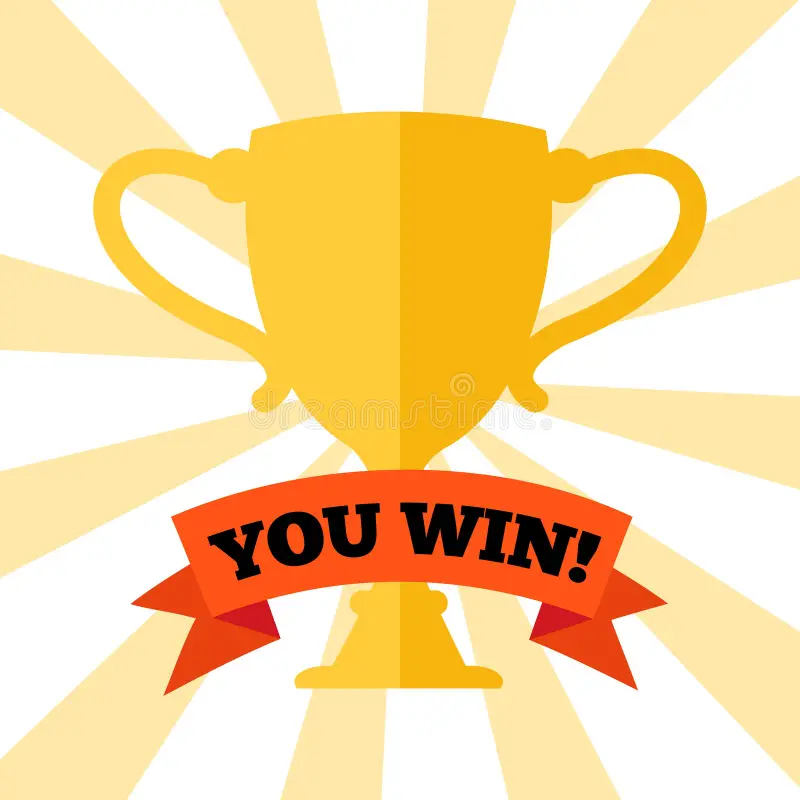

In [6]:
# Mostramos las instrucciones del juego
print("¡Bienvenido al Blackjack!♠️♥️♣️♦️")
print("El objetivo es acercarse a 21 puntos sin pasarse.")
print("Las cartas del 2 al 10 valen lo que indica su número.")
print("Las figuras J, Q y K valen 10 puntos.")
print("Los ases valen 11 o 1 para intentar no superar 21.")
print("Un blackjack son 21 puntos con las dos primeras cartas.")
print("El blackjack gana a un 21 conseguido con más cartas.")
print("La banca pide cartas con menos de 17 y se planta con 17 o más.")
print("Si ambos tienen blackjack, o los mismos puntos sin blackjack, hay empate.")
print("Escribe las respuestas en minúsculas.")
print ("¡Buena suerte!🃏")

# Preguntamos si quiere comenzar la partida
jugar = input("¿Quieres comenzar la partida? Escribe si o no: ")

# Si escribe una respuesta distinta, volvemos a preguntar
while jugar != "si" and jugar != "no":
    jugar = input("Escribe si o no en minúsculas y sin tilde: ")
    
#Importamos random para poder barajar las cartas
import random

#Importamos ramdom con display para las imágens de los resultados
from IPython.display import Image,display

#Definimos los posibles valores de las cartas (2 al 10, J,Q,K,A), multiplicandolo por 4 ya que son 4 palos y necesitamos 52 cartas
mazo = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"] * 4

#Barajamos el mazo
random.shuffle(mazo)

#Repartimos 2 cartas al jugador y las guardamos en una lista
# Cada mazo.pop () extrae la última carta del mazo y la elimina de él
mano_jugador = [mazo.pop(), mazo.pop()]

# Repartimos 2 cartas a la banca, extrayéndolas del mazo otra vez con mazo.pop()
mano_banca = [mazo.pop(), mazo.pop()]

#Definimos una función que nos calcula los puntos de una mano
def calcular_puntos(mano):
    puntos = 0
    ases = 0
    
    #Miramos cada carta de la mano para sumar su valor
    for carta in mano:
        if carta in ["J", "Q", "K"]:
            puntos = puntos + 10
        elif carta == "A":
            puntos = puntos + 11
            ases = ases + 1
        else:
            # Las cartas del 2 al 10 suman tantos puntos como indica su número, con int() convertimos el texto que contiene un número, en un número entero para poder hacer los cálculos
            puntos = puntos + int(carta)
            
    # Si superamos los 21 puntos y tenemos Ases contados como 11, ajustamos reduciendo cada As a 1 punto (-10)
    while puntos > 21 and ases > 0:
        puntos = puntos - 10
        ases = ases -1
        
    #Retornamos el total final calculado de puntos
    return puntos

# Mostramos las cartas del jugador y una carta de la banca
print("Tus cartas:", mano_jugador)
print("Tus puntos:", calcular_puntos(mano_jugador))
print("Carta visible de la banca:", mano_banca[0])

# La partida todavía no ha terminado
partida_terminada = False

# Comprobamos si ambos tienen blackjack en el reparto inicial
if calcular_puntos(mano_jugador) == 21 and calcular_puntos(mano_banca) == 21:
    print("Cartas de la banca:", mano_banca)
    print("¡Ambos tenéis blackjack! ¡Empate! 😲")
    display(Image(filename="empate.png",width=300))
    partida_terminada = True

elif calcular_puntos(mano_jugador) == 21:
    print("¡Blackjack! ¡Has ganado! 🏆")
    display(Image(filename="ganar.png",width=300))
    partida_terminada = True

elif calcular_puntos(mano_banca) == 21:
    print("Cartas de la banca:", mano_banca)
    print("La banca tiene blackjack. Gana la banca. 💩")
    display(Image(filename="perder.png",width=300))
    partida_terminada = True

else:
    # El jugador puede pedir cartas mientras tenga menos de 21 puntos
    while calcular_puntos(mano_jugador) < 21:
        opcion = input("¿Quieres pedir carta o plantarte? Escribe pedir o plantarse: ")

        if opcion == "pedir":
            # Sacamos una carta del mazo y la añadimos a su mano
            mano_jugador.append(mazo.pop())

            print("Tus cartas:", mano_jugador)
            print("Tus puntos:", calcular_puntos(mano_jugador))

        elif opcion == "plantarse":
            print("Te has plantado.")
            # Salimos del bucle y termina el turno del jugador
            break

        else:
            print("Escribe pedir o plantarse.")

# Al terminar el turno, comprobamos si el jugador se ha pasado
if calcular_puntos(mano_jugador) > 21:
    print("¡Te has pasado! Gana la banca. 💩")
    print("Cartas de la banca:", mano_banca)
    display(Image(filename="perder.png",width=300))
    partida_terminada = True
    
# La banca juega solo si la partida todavía no ha terminado
if partida_terminada == False:
    print("Cartas de la banca:", mano_banca)

    # La banca pide cartas mientras tenga menos de 17 puntos
    while calcular_puntos(mano_banca) < 17:
        mano_banca.append(mazo.pop())
        print("Cartas de la banca:", mano_banca)

    # Guardamos las puntuaciones finales
    puntos_jugador = calcular_puntos(mano_jugador)
    puntos_banca = calcular_puntos(mano_banca)

    print("Tus puntos finales:", puntos_jugador)
    print("Puntos finales de la banca:", puntos_banca)

    # Comparamos los resultados
    if puntos_banca > 21:
        print("¡La banca se ha pasado! ¡Has ganado! 🏆")
        display(Image(filename="ganar.png",width=300))
    elif puntos_jugador > puntos_banca:
        print("¡Has ganado!")
        display(Image(filename="ganar.png",width=300))
    elif puntos_jugador < puntos_banca:
        print("Gana la banca. 💩")
        display(Image(filename="perder.png",width=300))
    else:
        print("¡Empate! 😲")
        display(Image(filename="empate.png",width=300))
        

    # La partida termina después de anunciar el resultado
    partida_terminada = True
    
    